<a href="https://colab.research.google.com/github/Suzukuru/pendulum_diffeqdynamical/blob/main/Pendulum.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# README
Numerical approximation (Euler vs RK45) of a pendulum's swing. \
\
`F(t, S)` takes the time and state `S = [θ, ω]` and returns their rates of change. It is used by both Euler and `solve_ivp` (RK45) from SciPy.\
\
`euler(S_0, t_0, t_end, h)` takes the initial state, start time, end time and step size `h`, and returns the arrays `S` (state at every step) and `T` (the times).\
\
`energy(theta, omega)` applies the pendulum energy formula, E = ½ω² + (g/L)(1 − cos θ), and returns the energy at every step.
## Images
### Phase Portrait (x = θ, y = ω): Euler vs RK45
<img width="596" height="439" alt="image" src="https://github.com/user-attachments/assets/166e575d-b6f3-4977-adcf-c041f2324586" /> \
Euler here is gaining artificial energy over time due to it overshooting over multiple steps resulting in it spiraling out and getting larger and larger. RK45 is more stable maintaining a closed loop. \
\
This artificial energy gain is more clearly seen using energy function and plot it over time.
### Energy curve (x = t, y = Energy): Euler vs RK45
<img width="608" height="452" alt="image" src="https://github.com/user-attachments/assets/8d130c47-f3d5-465b-b0b2-6211631ea41b" />


# Imports

In [10]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from scipy.integrate import solve_ivp
import scipy as sp
import math

# Functions and Constants

In [11]:
g = 9.8
L = 1.0 # length of pendulum
h = 0.001 # step_size

def F(t, S):
  theta, omega = S[0], S[1]
  d_theta = omega
  d_omega = (-g/L) * np.sin(theta)
  return np.array([d_theta, d_omega])

def euler(S_0, t_0, t_end, h):
  n_steps = int(math.ceil((t_end-t_0)/h - 1e-9))
  S = np.empty((n_steps+1, S_0.shape[0]))
  T = np.empty(n_steps + 1)
  S[0], T[0] = S_0, t_0

  for k in range(n_steps):
    steps = min(h, t_end - T[k])
    S[k + 1] = S[k] + (steps*F(T[k], S[k]))
    T[k + 1] = T[k] + steps
  return S, T

def energy(theta, omega):
  return 0.5 * omega**2 + (g/L)*(1-np.cos(theta))

# Calculated Euler states and RK45 states

In [12]:
theta_0, omega_0 = 0.2, 0.0 # initial states
S_0 = np.array([theta_0, omega_0])

# Euler Numerical Method
S, T = euler(S_0, 0, 200, h)

# RK45 Numerical Method explicit t size and tighter tolerance, uses T (t_end (200) / h (0.001)) from Euler for t size
sol_final = solve_ivp(F, (0, 200), S_0, t_eval=np.clip(T, 0, 200), rtol=1e-9, atol=1e-12, method='RK45')

# Euler (unstable) vs RK45 (stable) θ over time

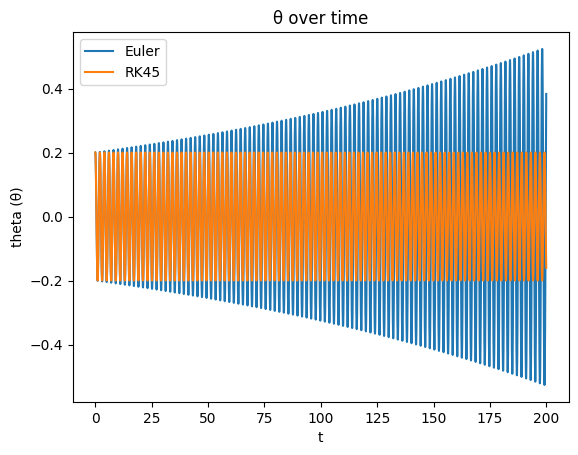

In [13]:
plt.xlabel("t")
plt.ylabel("theta (θ)")
plt.title("θ over time")
plt.plot(T, S[:, 0], label="Euler")
plt.plot(sol_final.t, sol_final.y[0], label="RK45")
plt.legend()

### Accuracy Comparison of `solve_ivp` Configurations

| Configuration | Actual Mathematical Accuracy (Error Drift) | Visually Accurate? (Looks Accurate) | Explanation |
| :--- | :--- | :--- | :--- |
| **Loose tolerance, no `t_eval`** | **Low** (Uses large default steps, leading to cumulative phase drift over long periods like $t=200$) | **No** (Plotting only at sparse solver step-points makes the curve look jagged and distorted) |
| **Loose tolerance, with `t_eval`** | **Low** (Interpolated on $T$, but underlying solver steps are still loose and accumulate error) | **Yes** (Looks smooth and visually resembles the correct curve because it is evaluated on a fine grid, though it suffers from phase shift/drift) |
| **Tight tolerance, no `t_eval`** | **High** (Tight tolerance forces the solver to take small, highly accurate steps) | **Yes** (The solver naturally takes enough small steps—over 12,000—to make the resulting plot look perfectly smooth) |
| **Tight tolerance, with `t_eval`** | **High** (Highly accurate internal solver steps with tight tolerances) | **Yes** (Both mathematically precise and visually smooth on the evaluation grid) |

649 0.32134824870005474
200001 0.0010000000000047748
12431 0.01918931241653965
200001 0.0010000000000047748


Text(0.5, 1.0, 'θ over time')

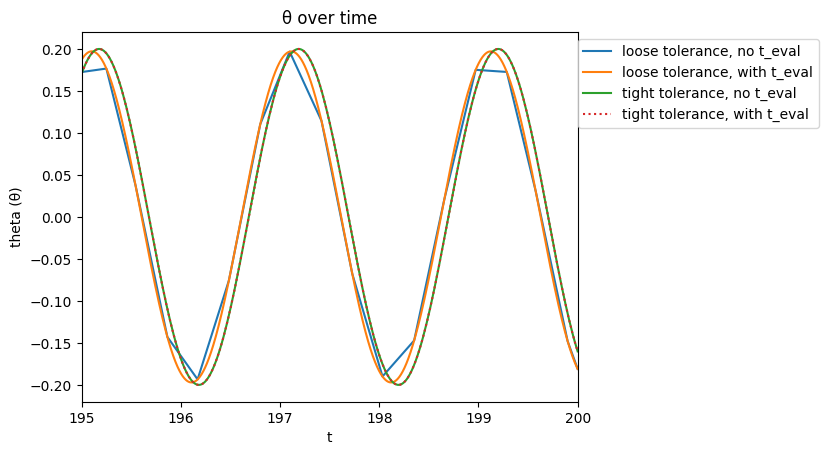

In [14]:
# Loose tolerance, no t_eval
sol_loose = solve_ivp(F, (0, 200), S_0, method='RK45')
print(len(sol_loose.t), np.diff(sol_loose.t).max())
plt.plot(sol_loose.t, sol_loose.y[0], label="loose tolerance, no t_eval")

# Loose tolerance, with t_eval
sol_loose_eval = solve_ivp(F, (0, 200), S_0, t_eval=np.clip(T, 0, 200), method='RK45')
print(len(sol_loose_eval.t), np.diff(sol_loose_eval.t).max())
plt.plot(sol_loose_eval.t, sol_loose_eval.y[0], label="loose tolerance, with t_eval")

# Tight tolerance, no t_eval
sol_tight = solve_ivp(F, (0, 200), S_0, rtol=1e-9, atol=1e-12, method='RK45')
print(len(sol_tight.t), np.diff(sol_tight.t).max())
plt.plot(sol_tight.t, sol_tight.y[0], label="tight tolerance, no t_eval")

# Tight tolerance, with t_eval
sol_tight_eval = solve_ivp(F, (0, 200), S_0, t_eval=np.clip(T, 0, 200), rtol=1e-9, atol=1e-12, method='RK45')
print(len(sol_tight_eval.t), np.diff(sol_tight_eval.t).max())
plt.plot(sol_tight_eval.t, sol_tight_eval.y[0], label="tight tolerance, with t_eval", linestyle=':')

plt.xlim(195, 200)
plt.legend(bbox_to_anchor=(1.5, 1))
plt.xlabel("t")
plt.ylabel("theta (θ)")
plt.title("θ over time")

# Phase Portrait: Euler vs RK45 (x = θ, y = ω)

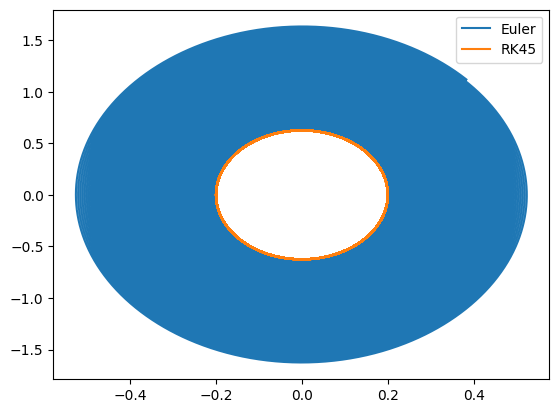

In [15]:
plt.plot(S[:,0], S[:,1], label="Euler")
plt.plot(sol_final.y[0], sol_final.y[1], label="RK45")
plt.legend()

# Energy Curve: Euler vs RK45

1.3359357214554026 0.19534750729052003
0.19534753715583217 0.19534738781716154


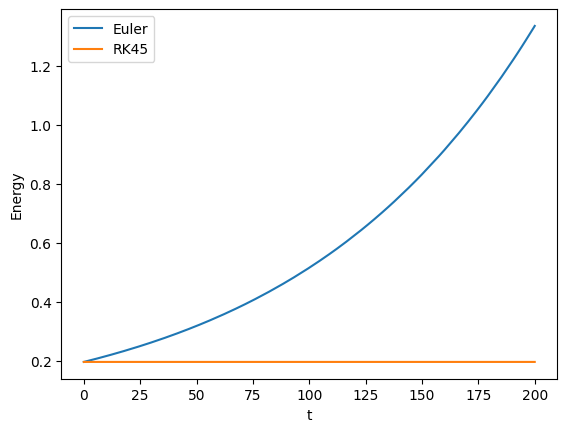

In [16]:
euler_energy = energy(S[:,0], S[:,1])
rk45_energy = energy(sol_final.y[0], sol_final.y[1])

plt.plot(T, euler_energy, label="Euler")
plt.plot(T, rk45_energy, label="RK45")
plt.xlabel("t")
plt.ylabel("Energy")
plt.legend()

print(euler_energy[-1], rk45_energy[-1])

sol_1000 = solve_ivp(F, (0, 1000), S_0, rtol=1e-9, atol=1e-12, method='RK45')
rk45_energy_1000 = energy(sol_1000.y[0], sol_1000.y[1])
print(rk45_energy_1000[1], rk45_energy_1000[-1])